<a href="https://colab.research.google.com/github/sofyadmitrieva/Deep-learning/blob/main/%D0%A1%D0%BB%D0%B8%D0%BF%D1%87%D0%B5%D0%BD%D0%BA%D0%BE_hw_transformers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнее задание: самостоятельное освоение Hugging Face Transformers

Цель: разобрать официальные туториалы Hugging Face по тонкой настройке трансформеров, выбрать тему классификации текста, обучить модель и подготовить отчёт. Мультимодальные системы разбираются отдельно на следующем занятии.

## Часть 1. Самостоятельный разбор туториалов Hugging Face

**Text classification task guide**
https://huggingface.co/docs/transformers/tasks/sequence_classification

**1. Что делает данный компонент/функция.**

Гайд описывает пайплайн дообучения DistilBERT на датасете IMDb, чтобы определять тональность отзыва, а затем применять обученную модель для inference.

**2. Какие параметры критичны для классификации текста и почему.**
Для классификации особенно важны AutoTokenizer и параметр truncation=True, которые обеспечивают преобразование текста в токены и ограничение длины последовательности, а также num_labels, id2label и label2id, задающие количество классов и соответствие между числовыми метками и названиями категорий. При обучении также важны learning_rate, per_device_train_batch_size, num_train_epochs и weight_decay, поскольку они влияют на скорость и качество обучения модели

**3. Один пример кода из туториала, который вы планируете использовать.**


```
from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

id2label = {0: "NEGATIVE", 1: "POSITIVE"}
label2id = {"NEGATIVE": 0, "POSITIVE": 1}

model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert/distilbert-base-uncased",
    num_labels=2,
    id2label=id2label,
    label2id=label2id
)

training_args = TrainingArguments(
    output_dir="my_model",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    num_train_epochs=2,
    weight_decay=0.01,
    eval_strategy="epoch"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

trainer.train()
```



**Trainer documentation**
https://huggingface.co/docs/transformers/main_classes/trainer

1. **Что делает данный компонент/функция.**

предназначен для обучения, оценки и получения предсказаний моделей машинного обучения на базе PyTorch. Он автоматизирует основной цикл обучения, включая обработку батчей, вычисление функции потерь, обновление весов модели и оценку результатов.

2. **Какие параметры критичны для классификации текста и почему.**

Для классификации текста наиболее важны параметры model (обучаемая модель), train_dataset (обучающая выборка), eval_dataset (валидационная выборка), processing_class (токенизатор) и compute_metrics (функция подсчета метрик качества). Дополнительно через TrainingArguments задаются learning_rate, per_device_train_batch_size, num_train_epochs, eval_strategy и weight_decay. Они определяют скорость обучения, размер батчей, количество эпох, периодичность оценки и регуляризацию модели, помогающую бороться с переобучением.

3. **Один пример кода из туториала, который вы планируете использовать.**



```
from transformers import Trainer, TrainingArguments

training_args = TrainingArguments(
    output_dir="./results",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

trainer.train()
results = trainer.evaluate()
```



**Datasets: load local CSV/JSON** https://huggingface.co/docs/datasets/loading
1. Что делает данный компонент/функция.
Библиотека Datasets предназначена для загрузки и подготовки датасетов из репозитория Hugging Face Hub, локальных файлов (CSV, JSON, TXT и др.) и других источников. Основная функция - load_dataset()

2. Какие параметры критичны для классификации текста и почему.

Особенно важны параметры data_files и split, позволяющие разделить данные на обучающую, валидационную и тестовую выборки, а также features, определяющий типы столбцов и классы целевой переменной. Например, ClassLabel(names=...) позволяет задать названия классов и связать их с числовыми метками, а Value("string") — указать, что столбец с текстами содержит строки. При загрузке CSV также могут понадобиться delimiter и column_names, если файл использует нестандартный разделитель или не содержит заголовков.

3. Один пример кода из туториала, который вы планируете использовать.



```
from datasets import load_dataset, Features, Value, ClassLabel

class_names = ["negative", "positive"]

features = Features({
    "text": Value("string"),
    "label": ClassLabel(names=class_names)
})

data_files = {
    "train": "train.csv",
    "validation": "validation.csv",
    "test": "test.csv"
}

dataset = load_dataset(
    "csv",
    data_files=data_files,
    features=features
)
```



**Evaluate: F1 metric**
https://huggingface.co/docs/evaluate/index

1. **Что делает данный компонент/функция.**

Библиотека Evaluate предназначена для оценки качества моделей машинного обучения и датасетов с помощью готовых метрик, например Accuracy, Precision, Recall и F1-score.

2. **Какие параметры критичны для классификации текста и почему.**

Ключевыми параметрами являются predictions (предсказанные моделью классы) и references (правильные метки из датасета), поскольку на их основе рассчитываются метрики качества. При использовании F1-score, Precision и Recall важно учитывать параметр average, определяющий способ усреднения результатов по классам, особенно при несбалансированных данных. При автоматической оценке через evaluator() также важны input_column, label_column и label_mapping, которые позволяют правильно определить столбцы с текстами и метками и сопоставить названия классов с числовыми значениями.

3. **Один пример кода из туториала, который вы планируете использовать.**

```
import evaluate

clf_metrics = evaluate.combine([
    "accuracy",
    "f1",
    "precision",
    "recall"
])

results = clf_metrics.compute(
    predictions=[0, 1, 0, 1],
    references=[0, 1, 1, 1]
)

print(results)
```

**Проверка понимания.**

**1. Чем problem_type="single_label_classification" отличается от "multi_label_classification" с точки зрения функции потерь?**

* single_label_classification - каждому тексту соответствует только один класс из нескольких возможных
* multi_label_classification — одному тексту можно присвоить несколько классов одновременно

**2. Зачем нужен processing_class=tok в Trainer (а не tokenizer=tok)?**

processing_class передает токенизатор или другой обработчик данных (например, image processor) в Trainer. Это позволяет автоматически использовать подходящий механизм формирования батчей и динамического дополнения последовательностей до одинаковой длины (padding), а также сохранить токенизатор вместе с обученной моделью для дальнейшего использования. При этом непосредственно токенизация исходных текстов выполняется заранее, например через tokenizer() и dataset.map().

**3. Что произойдёт, если не передать compute_metrics в Trainer?**

Обучение модели продолжится, но Trainer не будет автоматически рассчитывать дополнительные метрики Accuracy, Precision, Recall и F1-score. При наличии размеченной валидационной выборки он сможет вычислять значение функции потерь (eval_loss) и служебные показатели процесса оценки. Чтобы получить метрики качества классификации, необходимо самостоятельно определить функцию compute_metrics и передать ее в Trainer.

# Часть 2. Тема 1. Классификация новостей (датасет ag_news)

In [6]:
import torch

print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "GPU не найден")

True
Tesla T4


Transformers: 5.22.1
Device: cuda
GPU: Tesla T4


README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (20 outputs left out)

Лучшая модель сохранена.


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
0.128792,0.225128,3,0.943750,0.943803



Результаты оценки:
eval_loss: 0.2251
eval_accuracy: 0.9437
eval_f1_macro: 0.9438

Итоговая таблица:


,eval_accuracy,eval_f1_macro,eval_loss
0,0.94375,0.943803,0.225128


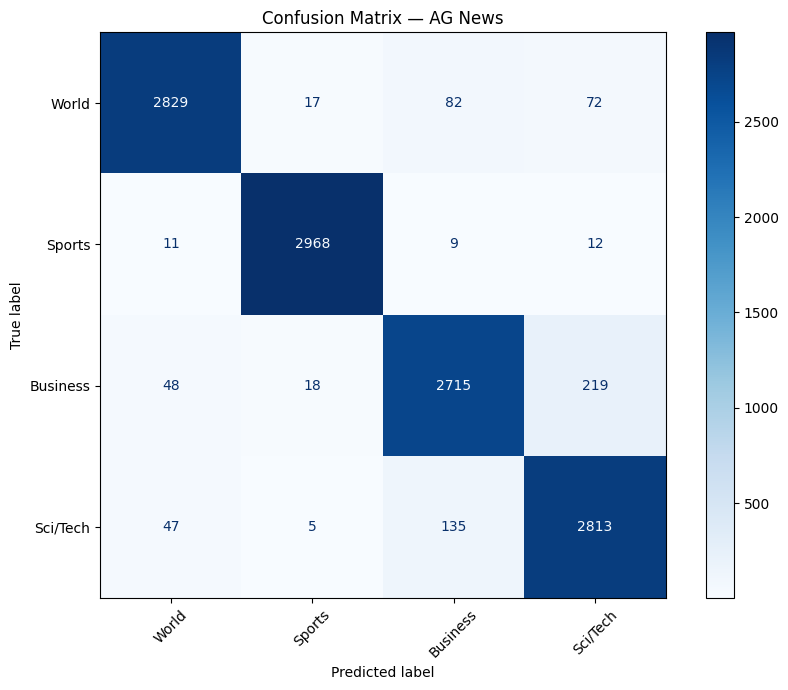


Три наиболее частые ошибки:
Business -> Sci/Tech: 219 ошибок
Sci/Tech -> Business: 135 ошибок
World -> Business: 82 ошибок


[transformers] early stopping required metric_for_best_model, but did not find eval_f1_macro so early stopping is disabled


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
0.128792,0.221642,3,0.944737,0.944838



Финальная проверка на test:
test_loss: 0.2216
test_accuracy: 0.9447
test_f1_macro: 0.9448


In [7]:

# 1. Установка и импорты

!pip install -q transformers datasets evaluate accelerate scikit-learn matplotlib

import torch
import numpy as np
import pandas as pd
import evaluate
import matplotlib.pyplot as plt

from datasets import load_dataset, DatasetDict

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback,
    DataCollatorWithPadding
)

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print("Transformers:", __import__("transformers").__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# 2. Загрузка данных

raw_datasets = load_dataset("fancyzhx/ag_news")

# Названия классов
label_names = raw_datasets["train"].features["label"].names
num_labels = len(label_names)

id2label = {i: name for i, name in enumerate(label_names)}
label2id = {name: i for i, name in id2label.items()}

# Выделяем validation из полной train-выборки
train_valid = raw_datasets["train"].train_test_split(
    test_size=0.1,
    seed=42,
    stratify_by_column="label"
)

# Создаем итоговый DatasetDict
datasets = DatasetDict({
    "train": train_valid["train"],
    "validation": train_valid["test"],
    "test": raw_datasets["test"]
})

# Trainer ожидает название labels
datasets = datasets.rename_column("label", "labels")

print("\nКлассы:", label_names)
print("\nРазмеры выборок:")

for split in datasets:
    print(f"{split}: {len(datasets[split])}")


# 3. Токенизация

checkpoint = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(checkpoint)

def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=128
    )

tokenized_datasets = datasets.map(
    tokenize_function,
    batched=True
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

# 4. Метрики

accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_metric.compute(
        predictions=predictions,
        references=labels
    )["accuracy"]

    f1_macro = f1_metric.compute(
        predictions=predictions,
        references=labels,
        average="macro"
    )["f1"]

    return {
        "accuracy": accuracy,
        "f1_macro": f1_macro
    }


# 5. Модель

model = AutoModelForSequenceClassification.from_pretrained(
    checkpoint,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id
)

model.config.problem_type = "single_label_classification"


# 6. Настройки обучения

training_args = TrainingArguments(
    output_dir="./ag_news_output",

    learning_rate=2e-5,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,

    num_train_epochs=3,

    weight_decay=0.01,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,

    metric_for_best_model="f1_macro",
    greater_is_better=True,

    save_total_limit=2,

    logging_steps=100,

    fp16=torch.cuda.is_available(),

    report_to="none",

    seed=42
)

# 7. trainer

trainer = Trainer(
    model=model,
    args=training_args,

    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],

    processing_class=tokenizer,
    data_collator=data_collator,

    compute_metrics=compute_metrics,

    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=2
        )
    ]
)


# 8. обучение

train_result = trainer.train()

print("\nОбучение завершено!")
print("Train loss:", round(train_result.training_loss, 4))


# 9. сохранение лучшей модели

trainer.save_model("./ag_news_distilbert_best")
tokenizer.save_pretrained("./ag_news_distilbert_best")

print("Лучшая модель сохранена.")


# 10. оценка лучшей модели на validation

eval_results = trainer.evaluate(
    tokenized_datasets["validation"]
)

print("\nРезультаты оценки:")

for key, value in eval_results.items():
    print(f"{key}: {value:.4f}")


# Таблица для отчета
results_table = pd.DataFrame([{
    "eval_accuracy": eval_results["eval_accuracy"],
    "eval_f1_macro": eval_results["eval_f1_macro"],
    "eval_loss": eval_results["eval_loss"]
}])

print("\nИтоговая таблица:")
display(results_table)


# 11. confusion matrix

predictions_output = trainer.predict(
    tokenized_datasets["validation"]
)

predictions = np.argmax(
    predictions_output.predictions,
    axis=-1
)

true_labels = predictions_output.label_ids

cm = confusion_matrix(
    true_labels,
    predictions,
    labels=list(range(num_labels))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_names
)

fig, ax = plt.subplots(figsize=(9, 7))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)

plt.title("Confusion Matrix — AG News")
plt.tight_layout()
plt.show()

# 12. 3 наиболее частые путаницы между классами

off_diagonal = cm.copy()
np.fill_diagonal(off_diagonal, 0)

error_pairs = []

for i in range(num_labels):
    for j in range(num_labels):
        if i != j and cm[i, j] > 0:
            error_pairs.append(
                (cm[i, j], label_names[i], label_names[j])
            )

error_pairs.sort(reverse=True)

print("\nТри наиболее частые ошибки:")

for count, true_class, predicted_class in error_pairs[:3]:
    print(
        f"{true_class} -> {predicted_class}: {count} ошибок"
    )


# 13. Дополнительная оценка на test

test_results = trainer.evaluate(
    tokenized_datasets["test"],
    metric_key_prefix="test"
)

print("\nФинальная проверка на test:")

for key, value in test_results.items():
    print(f"{key}: {value:.4f}")


# Часть 3. Анализ ошибок

In [8]:
# 1. Получаем предсказания модели на validation
predictions_output = trainer.predict(
    tokenized_datasets["validation"]
)

# 2. Определяем предсказанные и истинные классы
predictions = np.argmax(
    predictions_output.predictions,
    axis=-1
)

true_labels = predictions_output.label_ids

# 3. Находим индексы ошибочных предсказаний
error_indices = np.where(
    predictions != true_labels
)[0]

print("Всего ошибочных примеров:", len(error_indices))
print(
    "Доля ошибок:",
    f"{len(error_indices) / len(true_labels) * 100:.2f}%"
)

# 4. Случайным образом выбираем 5 ошибок
rng = np.random.default_rng(42)

selected_errors = rng.choice(
    error_indices,
    size=min(5, len(error_indices)),
    replace=False
)

# 5. Формируем таблицу
error_examples = []

for idx in selected_errors:

    original_text = datasets["validation"][int(idx)]["text"]

    true_class = label_names[int(true_labels[idx])]
    predicted_class = label_names[int(predictions[idx])]

    error_examples.append({
        "Текст (первые 100 символов)": original_text[:100],
        "Истинный класс": true_class,
        "Предсказанный класс": predicted_class,
        "Гипотеза о причине": ""
    })

errors_df = pd.DataFrame(error_examples)

# 6. Выводим таблицу
print("\nПять случайных ошибочных примеров:")
display(errors_df)

# 7. Сохраняем таблицу для отчёта
errors_df.to_csv(
    "ag_news_error_analysis.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Таблица сохранена в ag_news_error_analysis.csv")


Всего ошибочных примеров: 675
Доля ошибок: 5.62%

Пять случайных ошибочных примеров:


,Текст (первые 100 символов),Истинный класс,Предсказанный класс,Гипотеза о причине
0,Qualcomm plans to phone it in on cellular repa...,Sci/Tech,Business,
1,"Ads, Not Just Athletes, Were in Olympics Spotl...",Business,Sports,
2,Japanese carrier KDDI to tie up with BT on dat...,World,Sci/Tech,
3,Africa 'makes excuses on climate' African gove...,World,Sci/Tech,
4,French retailer Carrefour denies it is withdra...,World,Business,


Таблица сохранена в ag_news_error_analysis.csv


| Текст (первые 100 символов) | Истинный класс | Предсказанный класс | Гипотеза о причине |
|---|---|---|---|
| Qualcomm plans to phone it in on cellular repa... | Sci/Tech | Business | Смешение тематик Business / Sci-Tech: название коммерческой компании Qualcomm и упоминание корпоративных планов. |
| Ads, Not Just Athletes, Were in Olympics Spotl... | Business | Sports | Смешение тематик Business / Sports: упоминания Олимпиады и спортсменов. |
| Japanese carrier KDDI to tie up with BT on dat... | World | Sci/Tech | Узкоспециализированная телекоммуникационная лексика (carrier, data), а также названия KDDI и BT. |
| Africa 'makes excuses on climate' African gove... | World | Sci/Tech | Недостаток контекста в коротком заголовке и начало текста: слово climate могло вызвать ассоциацию с научно-экологической тематикой. |
| French retailer Carrefour denies it is withdra... | World | Business | Смешение тематик World / Business: слова retailer и withdrawing, а также название торговой сети Carrefour. |

# Часть 4. Подготовка к следующему занятию (мультимодальные системы)

**Вопрос для размышления.** В текстовой классификации вы передаёте в модель input_ids и attention_mask. В мультимодальной модели с изображением и текстом — что добавляется? Как вы думаете, почему Processor (а не Tokenizer) отвечает за подготовку входов?

В мультимодальной модели к input_ids и attention_mask добавляются pixel_values - тензор с обработанными данными изображения. В зависимости от архитектуры могут использоваться и дополнительные параметры, например image_grid_thw. Processor используется вместо обычного Tokenizer, поскольку он обрабатывает несколько типов данных одновременно: токенизирует текст, подготавливает изображения и формирует совместный вход для модели. Tokenizer предназначен преимущественно для обработки текста.
